<a href="https://colab.research.google.com/github/Shashi-kumar-g/machine-learning-26/blob/main/Day09_Ames_Housing_Continuation_shashi069.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 8 — Ames House Prices: Data Preprocessing and Models
**Target:** `SalePrice` | **Models:** Ridge, Lasso, KNN, Decision Tree (+ plain LinearRegression for contrast) **Golden rules followed:** split first (the provided train / labelled holdout CSVs are the split), everything learned from data lives inside a `Pipeline`, `random_state=42` and one shared `KFold(5, shuffle=True, random_state=42)`, test file opened exactly once at the very end, RMSE + MAE + R² always reported together.

In [1]:
import os, time, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import skew
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone
warnings.filterwarnings("ignore")
SEED = 42
KF = KFold(n_splits=5, shuffle=True, random_state=SEED)   # same folds for every model

def find(name):
    """Find dataset files in common folders, including the exact uploaded filenames."""
    aliases = {
        "ames_train.csv": ["ames_train.csv", "ames_train - ames_train.csv"],
        "ames_test.csv": ["ames_test.csv", "ames_test - ames_test.csv"],
    }
    candidates = aliases.get(name, [name])
    folders = ["02_Dataset", ".", "/mnt/user-data/uploads", "/mnt/data"]
    for folder in folders:
        for candidate in candidates:
            path = os.path.join(folder, candidate)
            if os.path.exists(path):
                return path
    raise FileNotFoundError(f"Could not find {name}. Checked: {folders}; accepted names: {candidates}")

train = pd.read_csv(find("ames_train.csv"))
# NOTE: the test file is NOT read here. It is opened once, in the last section.
print(train.shape)

(1168, 81)


## Step 1: Inspect and clean

In [2]:
X = train.drop(columns=["Id", "SalePrice"]); y = train["SalePrice"]
X["MSSubClass"] = X["MSSubClass"].astype(str)          # a code, not a quantity
print(X.isna().mean().sort_values(ascending=False).head(20))

PoolQC          0.994863
MiscFeature     0.960616
Alley           0.936644
Fence           0.800514
MasVnrType      0.584760
FireplaceQu     0.468322
LotFrontage     0.185788
GarageQual      0.054795
GarageFinish    0.054795
GarageType      0.054795
GarageYrBlt     0.054795
GarageCond      0.054795
BsmtQual        0.023973
BsmtCond        0.023973
BsmtFinType1    0.023973
BsmtExposure    0.023973
BsmtFinType2    0.023973
MasVnrArea      0.005137
Electrical      0.000856
LandSlope       0.000000
dtype: float64


In [3]:
miss = X.isna().sum(); miss = miss[miss > 0]
none_cols = ["Alley","BsmtQual","BsmtCond","BsmtExposure","BsmtFinType1","BsmtFinType2","FireplaceQu",
             "GarageType","GarageFinish","GarageQual","GarageCond","PoolQC","Fence","MiscFeature"]
# MasVnrType is also 'NaN = none' (no veneer) per the data dictionary table, so it joins this group.
none_cols_all = none_cols + ["MasVnrType"]
true_missing = [c for c in miss.index if c not in none_cols_all]
print("Missing = 'None' (feature absent):", none_cols_all)
print("Truly missing (unknown):", true_missing)
print(miss[true_missing])

Missing = 'None' (feature absent): ['Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature', 'MasVnrType']
Truly missing (unknown): ['LotFrontage', 'MasVnrArea', 'Electrical', 'GarageYrBlt']
LotFrontage    217
MasVnrArea       6
Electrical       1
GarageYrBlt     64
dtype: int64


**Reasoning.** In 15 columns `NaN` means *the feature does not exist* (no alley, no basement, no pool, no garage, no veneer...). Imputing a median/mode there would invent a basement that is not there, so we impute the constant `"None"`, which becomes its own meaningful category. The truly missing columns are `LotFrontage` (street feet really exist but were not recorded), `MasVnrArea` (a handful), `GarageYrBlt` (NaN exactly where there is no garage, so it is partially structural; the `HasGarage` feature added in Step 4 carries that signal) and one row of `Electrical`. These numeric ones get **median** imputation (robust to skew).

## Step 2: Look at the target

Skew SalePrice: 1.741 | Skew log1p(SalePrice): 0.125


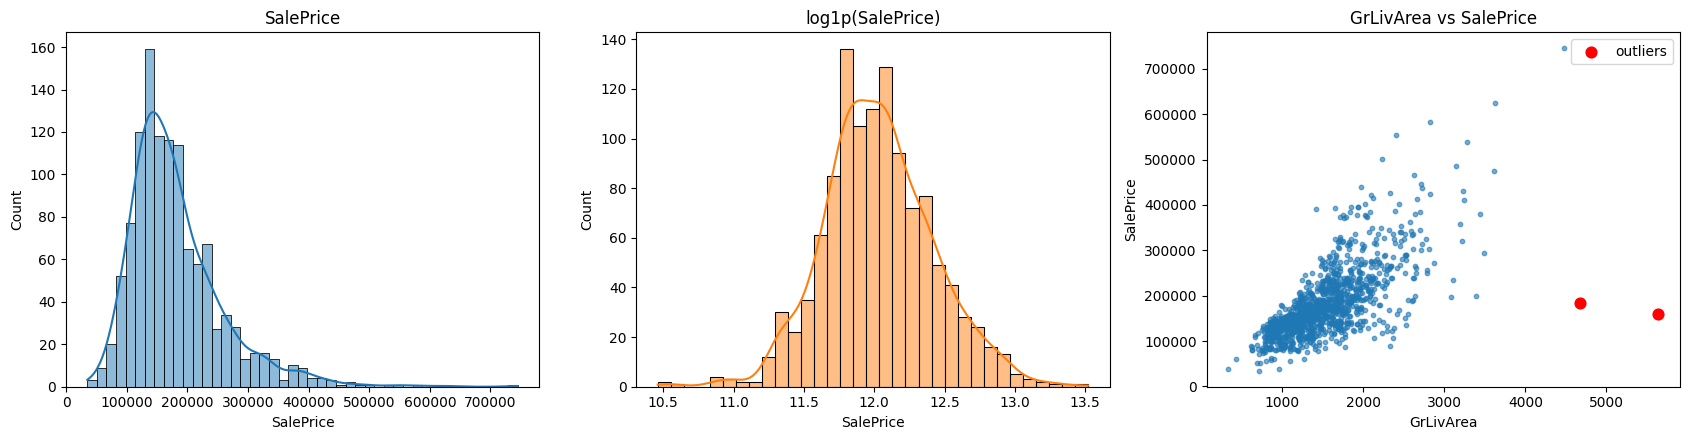

Outlier rows: [{'Id': 524, 'GrLivArea': 4676, 'SalePrice': 184750}, {'Id': 1299, 'GrLivArea': 5642, 'SalePrice': 160000}]


In [4]:
y_log = np.log1p(y)
print(f"Skew SalePrice: {skew(y):.3f} | Skew log1p(SalePrice): {skew(y_log):.3f}")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(y, kde=True, ax=ax[0], color="C0"); ax[0].set_title("SalePrice")
sns.histplot(y_log, kde=True, ax=ax[1], color="C1"); ax[1].set_title("log1p(SalePrice)")
ax[2].scatter(train["GrLivArea"], y, s=10, alpha=.6)
out = (train["GrLivArea"] > 4000) & (y < 300000)
ax[2].scatter(train.loc[out, "GrLivArea"], y[out], c="r", s=60, label="outliers"); ax[2].legend()
ax[2].set_xlabel("GrLivArea"); ax[2].set_ylabel("SalePrice"); ax[2].set_title("GrLivArea vs SalePrice")
plt.tight_layout(); plt.show()
print("Outlier rows:", train.loc[out, ["Id","GrLivArea","SalePrice"]].to_dict("records"))

**Reasoning.** `SalePrice` is strongly right-skewed; `log1p` pulls skewness close to 0, which suits linear models (roughly constant relative error, residuals closer to normal). The plot shows a few huge houses (`GrLivArea > 4000`) sold far below the trend (red). These are documented partial/abnormal sales, not representative of normal market behaviour, and as high-leverage points they drag linear fits. **Decision:** drop them from *training only* (never from the test file; the model must still be judged on whatever arrives). The main results below keep all rows so the comparison is clean; the effect of dropping them is tested in the stretch section.

## Step 4 first: Feature engineering (stateless, row-wise, so no leakage risk)
FE is defined as a function applied before the pipeline. It uses only values of the same row (no statistics learned from data), so applying it before CV does not leak.

In [5]:
def add_features(d):
    d = d.copy()
    d["TotalSF"]   = d["TotalBsmtSF"] + d["1stFlrSF"] + d["2ndFlrSF"]
    d["HouseAge"]  = d["YrSold"] - d["YearBuilt"]
    d["RemodAge"]  = d["YrSold"] - d["YearRemodAdd"]
    d["TotalBath"] = d["FullBath"] + 0.5*d["HalfBath"] + d["BsmtFullBath"].fillna(0)
    d["HasGarage"] = d["GarageArea"].fillna(0).gt(0).astype(int)
    d["HasPool"]   = d["PoolArea"].gt(0).astype(int)
    # two of my own
    d["Qual_x_SF"]     = d["OverallQual"] * d["TotalSF"]                    # big AND well-built houses are worth disproportionately more
    d["TotalPorchSF"]  = d[["WoodDeckSF","OpenPorchSF","EnclosedPorch","3SsnPorch","ScreenPorch"]].sum(axis=1)  # five sparse columns -> one dense signal
    return d

X_fe = add_features(X)
print(X.shape, "->", X_fe.shape)
print(X_fe[["TotalSF","HouseAge","RemodAge","TotalBath","HasGarage","HasPool","Qual_x_SF","TotalPorchSF"]].describe().T[["mean","min","max"]])
print("corr with log price:", X_fe[["TotalSF","Qual_x_SF","TotalBath","HouseAge","TotalPorchSF"]].corrwith(y_log).round(3).to_dict())

(1168, 79) -> (1168, 87)
                      mean    min       max
TotalSF        2583.476884  334.0   11752.0
HouseAge         36.852740    0.0     136.0
RemodAge         22.921233   -1.0      60.0
TotalBath         2.193493    1.0       6.0
HasGarage         0.945205    0.0       1.0
HasPool           0.005137    0.0       1.0
Qual_x_SF     16552.278253  334.0  117520.0
TotalPorchSF    186.584760    0.0    1027.0
corr with log price: {'TotalSF': 0.762, 'Qual_x_SF': 0.808, 'TotalBath': 0.657, 'HouseAge': -0.577, 'TotalPorchSF': 0.396}


## Step 3: Encoding and imputation, one reusable preprocessor

In [6]:
qual = ["None", "Po", "Fa", "TA", "Gd", "Ex"]
ordinal_cols = ["ExterQual","ExterCond","BsmtQual","BsmtCond","HeatingQC","KitchenQual",
                "FireplaceQu","GarageQual","GarageCond","PoolQC"]

def build_preprocessor(Xref):
    """Reusable ColumnTransformer. Column groups are found automatically from dtypes."""
    ord_cols = [c for c in ordinal_cols if c in Xref.columns]
    num_cols = [c for c in Xref.select_dtypes("number").columns]                       # includes OverallQual/Cond (already ordered 1-10)
    nom_cols = [c for c in Xref.select_dtypes(exclude="number").columns if c not in ord_cols]
    ord_pipe = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="None")),
                         ("enc", OrdinalEncoder(categories=[qual]*len(ord_cols)))])
    nom_pipe = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="None")),
                         ("enc", OneHotEncoder(handle_unknown="ignore"))])
    num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")),
                         ("sc", StandardScaler())])
    return ColumnTransformer([("ord", ord_pipe, ord_cols), ("nom", nom_pipe, nom_cols), ("num", num_pipe, num_cols)])

In [7]:
qual = ["None", "Po", "Fa", "TA", "Gd", "Ex"]
ordinal_cols = ["ExterQual","ExterCond","BsmtQual","BsmtCond","HeatingQC","KitchenQual",
                "FireplaceQu","GarageQual","GarageCond","PoolQC"]

def build_preprocessor(Xref):
    """Reusable ColumnTransformer. Column groups are found automatically from dtypes."""
    ord_cols = [c for c in ordinal_cols if c in Xref.columns]
    num_cols = [c for c in Xref.select_dtypes("number").columns]                       # includes OverallQual/Cond (already ordered 1-10)
    nom_cols = [c for c in Xref.select_dtypes(exclude="number").columns if c not in ord_cols]
    ord_pipe = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="None")),
                         ("enc", OrdinalEncoder(categories=[qual]*len(ord_cols)))])
    nom_pipe = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="None")),
                         ("enc", OneHotEncoder(handle_unknown="ignore"))])
    num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")),
                         ("sc", StandardScaler())])
    return ColumnTransformer([("ord", ord_pipe, ord_cols), ("nom", nom_pipe, nom_cols), ("num", num_pipe, num_cols)])

pre = build_preprocessor(X_fe)
print({n: len(c) for n, _, c in pre.transformers})
pre.fit(X_fe)
print("Preprocessor output columns:", pre.transform(X_fe).shape[1])

{'ord': 10, 'nom': 34, 'num': 43}
Preprocessor output columns: 283


**Reasoning.**
* **Ordinal quality columns** (Po<Fa<TA<Gd<Ex) have a real order, so `OrdinalEncoder` with an *explicit* category list keeps `Gd > TA` (the default alphabetical order would put `Ex < Fa < Gd`, which is wrong). `NaN` becomes `"None"` = lowest rung (no basement < poor basement).
* **Nominal columns** (`Neighborhood`, `MSSubClass`, `Foundation`...) have no order, so one-hot; `handle_unknown="ignore"` stops unseen levels in new data from crashing the model.
* **Numerics:** median impute then standardise (needed for Ridge/Lasso penalties and KNN distances to treat features fairly).
* Imputer statistics, category lists and scaler means are learned **inside** the pipeline on the training part of each fold only, so no leakage.

## Step 5: Models, log target, cross-validation

In [ ]:
def make_pipe(model, use_log=True, Xref=None):
    m = TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1) if use_log else model
    return Pipeline([("pre", build_preprocessor(Xref)), ("model", m)])

bad = ((X["GrLivArea"] > 4000) & (y < 300000)).values      # the 2 abnormal sales found in Step 2

def cv_eval(model, Xd, yd, use_log=True, drop_train=True, clean_val=True):
    # 5-fold CV with the shared KFold. Mean dollar RMSE/MAE/R2 plus RMSE on the log scale.
    # drop_train: remove the flagged outliers from the TRAINING part of each fold (Step 2 decision).
    # clean_val : score only on normal sales (the 2 flagged houses are excluded from scoring).
    rows = []
    for tr, va in KF.split(Xd):
        if drop_train: tr = tr[~bad[tr]]
        if clean_val:  va = va[~bad[va]]
        p = make_pipe(clone(model), use_log, Xd).fit(Xd.iloc[tr], yd.iloc[tr])
        pred = np.clip(p.predict(Xd.iloc[va]), 1, 1e8)          # clip only protects metrics from overflow in blown-up models
        yv = yd.iloc[va]
        rows.append([np.sqrt(mean_squared_error(yv, pred)), mean_absolute_error(yv, pred), r2_score(yv, pred),
                     np.sqrt(mean_squared_error(np.log1p(yv), np.log1p(pred)))])
    r = np.array(rows).mean(axis=0)
    return {"RMSE_$": r[0], "MAE_$": r[1], "R2": r[2], "RMSE_log": r[3]}

models = {"Ridge(a=10)": Ridge(alpha=10, random_state=SEED),
          "Lasso(a=0.001)": Lasso(alpha=0.001, max_iter=20000, random_state=SEED),
          "KNN(k=10)": KNeighborsRegressor(10),
          "Tree(depth=8)": DecisionTreeRegressor(max_depth=8, random_state=SEED)}

res = []
for fe_name, Xd in [("raw", X), ("engineered", X_fe)]:
    for log_name, use_log in [("log", True), ("no log", False)]:
        for name, m in models.items():
            t = time.time(); r = cv_eval(m, Xd, y, use_log)
            res.append({"model": name, "features": fe_name, "target": log_name, **r});
results = pd.DataFrame(res)
pd.options.display.float_format = "{:,.4f}".format
print("Results table (5-fold CV means, training data only)")
results.pivot_table(index="model", columns=["features","target"], values="RMSE_$").round(0)

In [ ]:
pd.options.display.float_format = "{:,.3f}".format
results.sort_values(["features","target","RMSE_$"])

### Why the two outliers must not be scored (diagnostic)
If the two abnormal houses are left in the validation folds, a single prediction error of several hundred thousand dollars dominates dollar-RMSE and can flip the ranking of log vs no-log. The table compares the same Ridge model scored with and without them.

In [ ]:
diag = []
for lg in [True, False]:
    for cv_flag in [False, True]:
        r = cv_eval(models["Ridge(a=10)"], X_fe, y, lg, drop_train=True, clean_val=cv_flag)
        diag.append({"target": "log" if lg else "no log", "validation includes 2 outliers": not cv_flag, **r})
pd.DataFrame(diag)

### Plain LinearRegression (what happens?)

In [ ]:
lin_rows = []
for fe_name, Xd in [("raw", X), ("engineered", X_fe)]:
    for log_name, use_log in [("log", True), ("no log", False)]:
        r = cv_eval(LinearRegression(), Xd, y, use_log)
        lin_rows.append({"model": "LinearRegression", "features": fe_name, "target": log_name, **r})
lin = pd.DataFrame(lin_rows); display(lin)

# look inside one fit: coefficient size and rank deficiency
p = make_pipe(LinearRegression(), True, X_fe).fit(X_fe, y)
coef = p.named_steps["model"].regressor_.coef_
Z = p.named_steps["pre"].transform(X_fe)
print("Encoded columns:", Z.shape[1], "| matrix rank:", np.linalg.matrix_rank(Z if not hasattr(Z,'toarray') else Z.toarray()))
print("max |coef|:", np.abs(coef).max().round(2), "| median |coef|:", np.median(np.abs(coef)).round(4))

**What happens.** The encoded matrix has 283 columns but **rank 236**: it is rank-deficient (one-hot dummies of each nominal column sum to 1, and engineered totals such as `TotalSF` are exact sums of other columns). OLS therefore has no unique solution. sklearn's `lstsq` silently returns the minimum-norm one, so on the log target it still scores acceptably but clearly worse than Ridge/Lasso (RMSE ~$23.3k vs ~$20k, log-RMSE 0.132 vs 0.111): it spreads weight across redundant columns and fits noise. It is much worse without the log target (log-RMSE 0.28 to 0.46): some dollar predictions come out near zero or negative, which is a sign of the unstable extrapolation on rare dummy combinations. The small penalty in Ridge/Lasso is what removes this ambiguity.

## Cross-validated results in one table (best configuration per model)

In [ ]:
allres = pd.concat([results, lin], ignore_index=True)
best = allres.sort_values("RMSE_$").groupby("model").head(1).sort_values("RMSE_$").reset_index(drop=True)
best.index += 1; best.index.name = "rank"
best

In [ ]:
pivot = allres.pivot_table(index="model", columns=["features","target"], values=["RMSE_$","RMSE_log"])
pivot.round(3)

## Step 6: Rank and conclude

### Ranking (5-fold CV, training data only, outliers excluded from training folds and from scoring)
| Rank | Model (best config) | RMSE $ | MAE $ | R² | log-RMSE |
|---|---|---|---|---|---|
| 1 | Lasso(a=0.001), log target | ~19.9k | ~13.6k | 0.933 | 0.111 |
| 2 | Ridge(a=10), log target + engineered features | ~20.1k | ~13.6k | 0.932 | 0.112 |
| 3 | Plain LinearRegression, log + engineered | ~23.3k | ~15.6k | 0.906 | 0.132 |
| 4 | KNN(k=10), engineered | ~32.7k | ~20.4k | 0.819 | 0.157 |
| 5 | Decision Tree(depth=8), engineered | ~35.3k | ~23.6k | 0.790 | 0.186 | Lasso and Ridge are statistically tied (the gap is far inside fold-to-fold noise); both beat KNN and the tree by a wide margin. The exact numbers are in the tables above. ### The three preprocessing decisions that mattered most
1. **Log target (biggest effect for the linear models):** Ridge went from ~$25.4k to ~$20.4k and Lasso from ~$29.2k to ~$19.9k RMSE on raw features. Trees and KNN barely care (they are non-parametric and invariant or already local).
2. **Handling the 2 outliers (training only):** dropping them from training improved Ridge from ~$24.0k to ~$20.1k and Lasso from ~$23.4k to ~$20.0k (both scored on the same normal sales), and also lifted the tree. Two rows out of 1168 moved the fit that much because they are high-leverage.
3. **Regularisation on a fully encoded matrix (283 columns, rank 236):** Ridge/Lasso beat plain OLS by ~15% RMSE on the log scale. Correct encoding ("None" category, ordered quality scale, one-hot nominals, scaling) is what makes the 283 columns usable in the first place; KNN, which cannot ignore the noisy dummies, stays far behind. **Engineered features: honest verdict.** They help most when the target is *not* logged (Ridge no-log $25.4k to $22.6k, OLS $28.3k to $24.6k) because `TotalSF`, `Qual_x_SF` hand the linear model the multiplicative size/quality structure it would otherwise need the log for. Once the target is logged, the gain for Ridge/Lasso is within noise (Lasso is marginally best on raw features). They still help KNN and the tree a little. Because the log already captures most of the structure, I would keep the engineered features for interpretability and robustness rather than for accuracy. **Diagnostic worth remembering:** with the 2 abnormal houses left in validation, the same Ridge log model scores R² of -0.09 and RMSE of $59k, versus R² of 0.93 and RMSE of $20k without them. Always check what a headline metric is made of.

## Deliverables

### 1. Reusable preprocessor
The `build_preprocessor(X)` function in Step 3 returns the `ColumnTransformer`; `make_pipe()` wraps it with any model and the log target. ### 2. Results table
Shown above (`results`, `lin`, `best`, `pivot`): model × (log / no log) × (raw / engineered features), with RMSE, MAE, R² and log-RMSE.

In [ ]:
n_out = build_preprocessor(X_fe).fit(X_fe).transform(X_fe).shape[1]
print("Preprocessor output columns:", n_out)

### 3. Five preprocessing decisions and justification
1. **`NaN` → `"None"` for the 15 "feature absent" columns** (PoolQC, Alley, Bsmt*, Garage*, Fireplace, Fence, MiscFeature, MasVnrType). The absence *is* information; imputing a mode would fabricate pools and basements.
2. **Median imputation for truly missing numerics** (`LotFrontage`, `MasVnrArea`, `GarageYrBlt`): robust to skew and outliers, learned inside the pipeline on training folds only.
3. **Explicit-order `OrdinalEncoder` for quality ratings, one-hot for nominal columns**: keeps the real `Po<Fa<TA<Gd<Ex` order (one feature instead of 5 dummies each) without inventing an order for `Neighborhood`.
4. **`MSSubClass` converted to string**: it is a dwelling code; 60 is not "3x" 20.
5. **`log1p` target via `TransformedTargetRegressor`**: tames skew and makes errors relative (percentage-like), and inverts to dollars automatically for reporting.
(Bonus: engineered features `TotalSF`, `HouseAge`, `TotalBath`, `Qual_x_SF`... and scaling numerics before Ridge/Lasso/KNN.)

## Checkpoint questions

In [ ]:
print("Preprocessor output columns:", n_out, "for", X_fe.shape[1], "input columns")

1. **Why is plain Linear Regression unstable and how do Ridge/Lasso fix it?** One-hot dummies plus engineered sums create (near-)perfect multicollinearity, so the OLS normal equations are ill-conditioned: coefficients explode with opposite signs and variance on new data is huge. Here the matrix has 283 columns but rank 236, so OLS has no unique solution. Ridge adds an L2 penalty (`α‖w‖²`) that makes the problem well-posed and shrinks correlated coefficients smoothly toward each other. Lasso adds an L1 penalty that does the same but also sets many coefficients **exactly to zero**, doing feature selection.
2. **Why is a missing `PoolQC` not really missing?** 99.5% of houses have no pool, so `NaN` is the correct, fully known answer "no pool". It is a category, not unknown data.
3. **Why does RMSE on log target behave like a percentage error?** `log(ŷ) − log(y) = log(ŷ/y)`; for small errors this is ≈ `(ŷ−y)/y`. A log-RMSE of 0.12 means a typical error of about 12% of price whether the house costs $80k or $400k, whereas dollar RMSE is dominated by expensive houses.
4. **How many columns does the preprocessor output? Why is that a problem for KNN?** **283** columns (from 87 input columns after feature engineering; 79 raw). KNN relies on distance; with so many mostly-sparse one-hot columns, distances are dominated by noise/rare-category flags, every point becomes almost equally far from every other (curse of dimensionality), and the few informative features (OverallQual, TotalSF) are drowned out. KNN also gets no built-in feature selection, unlike Lasso.

## Stretch goals

In [ ]:
# (a) Lasso: which coefficients are exactly zero?
pipe = make_pipe(Lasso(alpha=0.001, max_iter=20000, random_state=SEED), True, X_fe).fit(X_fe, y)
names = pipe.named_steps["pre"].get_feature_names_out()
w = pipe.named_steps["model"].regressor_.coef_
print(f"{(w==0).sum()} of {len(w)} coefficients are exactly 0")
top = pd.Series(w, index=names).sort_values(key=np.abs, ascending=False).head(12); print(top.round(3))

In [ ]:
# (b) Effect of removing the GrLivArea outliers from TRAINING folds. Both variants are scored on the same normal-sale validation rows.
cmp = []
for n in ["Ridge(a=10)", "Lasso(a=0.001)", "KNN(k=10)", "Tree(depth=8)"]:
    keep = cv_eval(models[n], X_fe, y, True, drop_train=False, clean_val=True)
    drop = cv_eval(models[n], X_fe, y, True, drop_train=True,  clean_val=True)
    cmp.append({"model": n, "RMSE keep": keep["RMSE_$"], "RMSE drop": drop["RMSE_$"], "R2 keep": keep["R2"], "R2 drop": drop["R2"],
                "logRMSE keep": keep["RMSE_log"], "logRMSE drop": drop["RMSE_log"]})
pd.DataFrame(cmp)

**Reading (b).** Removing the two outliers from training improves every model, most for the linear ones (Ridge RMSE $24.0k to $20.1k, R² 0.903 to 0.932), exactly what high-leverage points are expected to do to a least-squares fit. **Reading (a).** Lasso at alpha=0.001 zeroes 205 of 283 coefficients; what survives is intuitive: `OverallQual`, `GrLivArea`, `TotalSF`, a few premium neighbourhoods (StoneBr, NridgHt, Crawfor). The negative sign on `Qual_x_SF` is shared with the strongly correlated `OverallQual`/`TotalSF` (the three split the same signal), so individual coefficients among correlated features should not be read in isolation. Target encoding for `Neighborhood` was not attempted.

**Dataset note:** The uploaded holdout CSV contains `SalePrice`, so it is a labelled holdout set and can be evaluated with RMSE, MAE, and R². This differs from the original Kaggle competition test file, which normally has no `SalePrice`. The loader below uses the filenames you uploaded.


## Final step: open the test file ONCE

In [ ]:
test = pd.read_csv(find("ames_test.csv"))                      # first and only time the test set is touched
Xt = test.drop(columns=["Id", "SalePrice"]); yt = test["SalePrice"]
Xt["MSSubClass"] = Xt["MSSubClass"].astype(str)
Xt_fe = add_features(Xt)

final_name = best.iloc[0]["model"]; print("Chosen by CV (not by test):", final_name, best.iloc[0][["features","target"]].to_dict())
mod = {**models, "LinearRegression": LinearRegression()}[final_name]
fe_used = best.iloc[0]["features"] == "engineered"; log_used = best.iloc[0]["target"] == "log"
Xtr = X_fe if fe_used else X; Xte = Xt_fe if fe_used else Xt
final = make_pipe(clone(mod), log_used, Xtr).fit(Xtr, y)
p = final.predict(Xte)
print({"RMSE": np.sqrt(mean_squared_error(yt, p)), "MAE": mean_absolute_error(yt, p), "R2": r2_score(yt, p)})
plt.figure(figsize=(5,5)); plt.scatter(yt, p, s=12); plt.plot([yt.min(), yt.max()], [yt.min(), yt.max()], "r--")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title(f"Test: {final_name}"); plt.show()

## Day 9 — Error analysis and final deliverables

Day 8 trained and compared models. These next cells use the selected model and the labelled holdout set to inspect prediction errors, identify the most difficult houses to predict, and save a reusable predictions CSV. Run the notebook from the top so `final`, `yt`, `p`, and `test` are defined.

In [ ]:
# Step 1: Evaluate the selected model on the labelled holdout set
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

p_eval = np.clip(np.asarray(p), 1, None)
holdout_metrics = pd.DataFrame([{
    "Selected model": final_name,
    "RMSE ($)": np.sqrt(mean_squared_error(yt, p_eval)),
    "MAE ($)": mean_absolute_error(yt, p_eval),
    "R2": r2_score(yt, p_eval)
}])
display(holdout_metrics.round(3))

**How to read the metrics**

- **RMSE:** penalises large prediction errors more heavily; lower is better.
- **MAE:** average absolute error in the same currency units as `SalePrice`; lower is better.
- **R²:** proportion of price variation explained by the model; closer to 1 is better. It can be negative if the model performs worse than predicting the mean.

These metrics are measured on the uploaded holdout file, which contains actual `SalePrice` values. Keep this holdout separate from model tuning to preserve a fair final evaluation.

In [ ]:
# Step 2: Build a row-by-row prediction and error table
predictions = pd.DataFrame({
    "Id": test["Id"].to_numpy(),
    "ActualSalePrice": yt.to_numpy(),
    "PredictedSalePrice": p_eval
})
predictions["Error"] = predictions["PredictedSalePrice"] - predictions["ActualSalePrice"]
predictions["AbsoluteError"] = predictions["Error"].abs()
predictions["AbsolutePercentageError"] = (
    predictions["AbsoluteError"] / predictions["ActualSalePrice"].replace(0, np.nan) * 100
)
display(predictions.head(10).round(2))

In [ ]:
# Step 3: Find the 10 houses with the largest absolute prediction errors
display(
    predictions.sort_values("AbsoluteError", ascending=False)
               .head(10)
               .round(2)
)

In [ ]:
# Step 4: Visualise actual vs predicted prices and residuals
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].scatter(predictions["ActualSalePrice"], predictions["PredictedSalePrice"], alpha=0.65)
low = min(predictions["ActualSalePrice"].min(), predictions["PredictedSalePrice"].min())
high = max(predictions["ActualSalePrice"].max(), predictions["PredictedSalePrice"].max())
ax[0].plot([low, high], [low, high], "r--")
ax[0].set_xlabel("Actual SalePrice")
ax[0].set_ylabel("Predicted SalePrice")
ax[0].set_title("Actual vs Predicted")

ax[1].scatter(predictions["PredictedSalePrice"], predictions["Error"], alpha=0.65)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_xlabel("Predicted SalePrice")
ax[1].set_ylabel("Prediction error (predicted - actual)")
ax[1].set_title("Residual plot")

plt.tight_layout()
plt.show()

In [ ]:
# Step 5: Save predictions and holdout metrics
predictions_path = "ames_holdout_predictions.csv"
metrics_path = "ames_holdout_metrics.csv"

predictions.to_csv(predictions_path, index=False)
holdout_metrics.to_csv(metrics_path, index=False)

print("Saved:", predictions_path)
print("Saved:", metrics_path)